# UCS420: Cognitive Computing, Assignment 10
## Heart Health Information Assistant
**Name:** Kanan | **Roll No:** 1024170164

A Python-based healthcare cognitive assistant that understands user queries, identifies intent, retrieves heart-health information and generates responses.



## Setup: Libraries and NLTK Resources
Installs and imports the libraries for NLP (NLTK), machine learning (scikit-learn), visualisation (matplotlib, seaborn, networkx) and the interactive UI (ipywidgets).

In [1]:
!pip -q install nltk scikit-learn pandas matplotlib seaborn networkx ipywidgets
import re, nltk, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, networkx as nx
for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(p, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Requirement 1: Labelled Corpus
- Corpus of **98 queries** across **7 intent categories** (14 queries each)
- Intents: `symptoms`, `risk_factors`, `prevention`, `diet`, `medication`, `tests`, `emergency`
- Stored in a pandas DataFrame with columns `query` and `intent`

In [2]:
data = {
 "symptoms": [
  "What are the symptoms of a heart attack?", "What are the signs of heart failure?",
  "Why do I feel pain in my chest when I climb stairs?", "What are the warning signs of coronary artery disease?",
  "Is shortness of breath a sign of heart problems?", "What does heart palpitation feel like?",
  "Can swollen ankles indicate heart disease?", "What are common symptoms of arrhythmia?", "What are the early signs of a cardiac problem?", "Does left arm pain mean a heart problem?", "What are the symptoms of a mild heart attack in women?", "Can dizziness and fatigue be signs of heart disease?", "What does angina feel like?", "How do I know if my heart is not working properly?"],
 "risk_factors": [
  "What causes heart disease?", "Does smoking increase the risk of heart attack?",
  "Is high cholesterol a risk factor for heart disease?", "Can diabetes lead to heart problems?",
  "Who is at higher risk of cardiovascular disease?", "Does family history affect heart disease risk?",
  "How does obesity affect my heart?", "Is high blood pressure dangerous for the heart?", "What can make a person more likely to get heart problems?", "Are older people more prone to cardiac disease?", "Does alcohol increase heart disease risk?", "Which habits raise the chance of a heart attack?", "Is stress a risk factor for cardiovascular disease?", "Are men at greater risk of heart disease than women?"],
 "prevention": [
  "How can I prevent heart disease?", "What lifestyle changes keep my heart healthy?",
  "How much exercise is good for the heart?", "Does quitting smoking improve heart health?",
  "How can I reduce stress to protect my heart?", "How do I keep my heart strong as I age?",
  "Is walking daily good for the heart?", "How can I lower my risk of a heart attack?", "What daily habits protect my heart?", "How can I keep my heart healthy for life?", "Does yoga help the heart?", "How can I avoid getting a heart attack?", "Does good sleep protect heart health?", "What steps reduce the chance of cardiac disease?"],
 "diet": [
  "What foods are good for heart health?", "Which foods should I avoid with high cholesterol?",
  "Is a low salt diet good for the heart?", "Can eating fish help my heart?",
  "What is the best diet for heart patients?", "Are eggs bad for heart health?",
  "Should I reduce sugar and fat for my heart?", "What is the DASH diet?", "Which meals are best for keeping my heart healthy?", "What should I eat to protect my heart?", "Is butter or ghee bad for the heart?", "Are nuts and oats good for cholesterol?", "Which foods should heart patients avoid?", "Does eating less salt help my heart?"],
 "medication": [
  "What medicines are used to treat high blood pressure?", "What do statins do?",
  "What are the side effects of beta blockers?", "Why is aspirin given to heart patients?",
  "What is the purpose of blood thinners?", "How do ACE inhibitors work?",
  "Which tablets lower cholesterol?", "Do heart medications have side effects?", "Which drugs are prescribed for heart disease?", "How do blood pressure tablets work?", "What are the side effects of statins?", "Why do heart patients take blood thinners?", "What is the use of nitroglycerin tablets?", "What does clopidogrel do?"],
 "tests": [
  "How is heart disease diagnosed?", "What is an ECG test?", "What does an echocardiogram show?",
  "How is blood pressure measured?", "What is a stress test for the heart?",
  "Which blood tests check heart health?", "What is an angiogram?", "When should I get my cholesterol checked?", "How do doctors check if my heart is healthy?", "What does a lipid profile test measure?", "What is a Holter monitor test?", "Which scan shows heart blockages?", "How is a heart attack confirmed in hospital?", "What is a troponin blood test?"],
 "emergency": [
  "I have severe chest pain right now", "My father collapsed and is unconscious",
  "I think I am having a heart attack", "Chest pain spreading to my left arm and jaw",
  "I cannot breathe and my chest is tight", "Someone fainted and has no pulse",
  "Sudden crushing pressure in my chest", "What should I do during a heart attack emergency?", "My mother has sudden chest tightness and is sweating heavily", "Someone is not breathing and has no heartbeat", "He is clutching his chest and fell down", "Severe pain in chest and left shoulder, what do I do", "What to do if someone has a cardiac arrest?", "I feel crushing chest pain and am sweating"],
}
df = pd.DataFrame([(q, i) for i, qs in data.items() for q in qs], columns=["query", "intent"])
print(df.shape); print(df.intent.value_counts())

(98, 2)
intent
symptoms        14
risk_factors    14
prevention      14
diet            14
medication      14
tests           14
emergency       14
Name: count, dtype: int64


## Requirement 2: Hierarchical Taxonomy
- **4 major categories**, each with **2 subcategories** (8 in total)
- Every intent is mapped to a category and subcategory (`INTENT_TAXONOMY`)

| Category | Subcategories |
|---|---|
| Condition Awareness | Symptoms, Risk Factors |
| Prevention & Lifestyle | Physical Activity & Habits, Diet & Nutrition |
| Diagnosis & Treatment | Diagnostic Tests, Medications |
| Emergency Care | Warning Signs, Immediate Actions |

## Requirement 3: Domain Concepts and Relationships
- **15 domain concepts** (e.g. Smoking, Atherosclerosis, Hypertension, Statins, ECG)
- **13 relationships** stored as (subject, relation, object) triples
- Visualised as a directed concept graph, and later used for reasoning in the assistant

15 concepts: ['Atherosclerosis', 'Beta Blockers', 'Chest Pain', 'Coronary Artery Disease', 'Diabetes', 'ECG', 'Exercise', 'Healthy Diet', 'Heart Attack', 'Heart Failure', 'High Cholesterol', 'Hypertension', 'Obesity', 'Smoking', 'Statins']
13 relationships


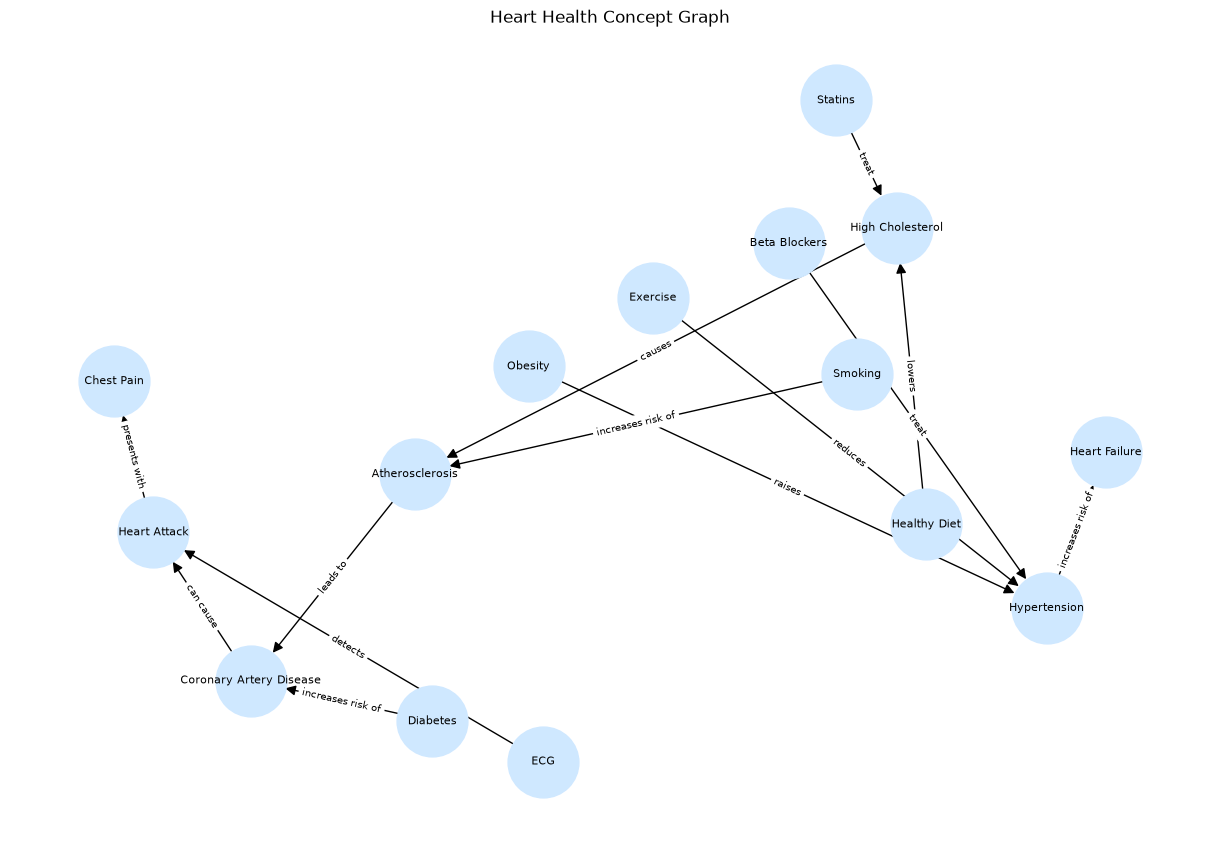

In [3]:
TAXONOMY = {
 "Condition Awareness":      ["Symptoms", "Risk Factors"],
 "Prevention & Lifestyle":   ["Physical Activity & Habits", "Diet & Nutrition"],
 "Diagnosis & Treatment":    ["Diagnostic Tests", "Medications"],
 "Emergency Care":           ["Warning Signs", "Immediate Actions"],
}
INTENT_TAXONOMY = {
 "symptoms": ("Condition Awareness", "Symptoms"),
 "risk_factors": ("Condition Awareness", "Risk Factors"),
 "prevention": ("Prevention & Lifestyle", "Physical Activity & Habits"),
 "diet": ("Prevention & Lifestyle", "Diet & Nutrition"),
 "tests": ("Diagnosis & Treatment", "Diagnostic Tests"),
 "medication": ("Diagnosis & Treatment", "Medications"),
 "emergency": ("Emergency Care", "Immediate Actions"),
}
TRIPLES = [
 ("Smoking", "increases risk of", "Atherosclerosis"),
 ("High Cholesterol", "causes", "Atherosclerosis"),
 ("Atherosclerosis", "leads to", "Coronary Artery Disease"),
 ("Coronary Artery Disease", "can cause", "Heart Attack"),
 ("Heart Attack", "presents with", "Chest Pain"),
 ("Hypertension", "increases risk of", "Heart Failure"),
 ("Obesity", "raises", "Hypertension"),
 ("Diabetes", "increases risk of", "Coronary Artery Disease"),
 ("Exercise", "reduces", "Hypertension"),
 ("Healthy Diet", "lowers", "High Cholesterol"),
 ("Statins", "treat", "High Cholesterol"),
 ("ECG", "detects", "Heart Attack"),
 ("Beta Blockers", "treat", "Hypertension"),
]
concepts = sorted({t[0] for t in TRIPLES} | {t[2] for t in TRIPLES})
print(len(concepts), "concepts:", concepts)
print(len(TRIPLES), "relationships")

G = nx.DiGraph()
for s, r, o in TRIPLES: G.add_edge(s, o, label=r)
plt.figure(figsize=(12, 8)); pos = nx.spring_layout(G, seed=3, k=1.2)
nx.draw(G, pos, with_labels=True, node_color="#cfe8ff", node_size=2600, font_size=8, arrowsize=15)
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), font_size=7)
plt.title("Heart Health Concept Graph"); plt.show()

## Requirement 4: NLP Preprocessing
Steps applied to every query:
1. **Lowercase conversion**
2. **Tokenization** (NLTK `word_tokenize`)
3. **Stopword removal** (NLTK English stopwords, keeping "no" and "not")
4. **Lemmatization** (WordNetLemmatizer, verb then noun)

In [4]:
lemm = WordNetLemmatizer()
STOPS = set(stopwords.words("english")) - {"no", "not"}

def preprocess(text):
    tokens = word_tokenize(text.lower().replace("’", "'"))
    tokens = [t for t in tokens if t.isalpha() and t not in STOPS]
    return " ".join(lemm.lemmatize(lemm.lemmatize(t, "v"), "n") for t in tokens)

df["clean"] = df["query"].apply(preprocess)
print(df[["query", "clean"]].head(5).to_string())

                                                    query                                clean
0                What are the symptoms of a heart attack?                 symptom heart attack
1                    What are the signs of heart failure?                   sign heart failure
2     Why do I feel pain in my chest when I climb stairs?          feel pain chest climb stair
3  What are the warning signs of coronary artery disease?    warn sign coronary artery disease
4        Is shortness of breath a sign of heart problems?  shortness breath sign heart problem


## Requirement 5: Feature Extraction and Classifier
- **TF-IDF** (unigram features) for feature extraction
- **Logistic Regression** as the classifier
- 75/25 stratified train-test split

## Requirement 6: Model Evaluation
- Accuracy, precision, recall and F1-score (classification report)
- Confusion matrix heatmap
- The final model is retrained on the full corpus for use in the assistant

Accuracy: 0.68
              precision    recall  f1-score   support

        diet       0.67      0.67      0.67         3
   emergency       0.50      0.33      0.40         3
  medication       0.67      1.00      0.80         4
  prevention       0.43      0.75      0.55         4
risk_factors       1.00      0.50      0.67         4
    symptoms       1.00      0.67      0.80         3
       tests       1.00      0.75      0.86         4

    accuracy                           0.68        25
   macro avg       0.75      0.67      0.68        25
weighted avg       0.76      0.68      0.68        25



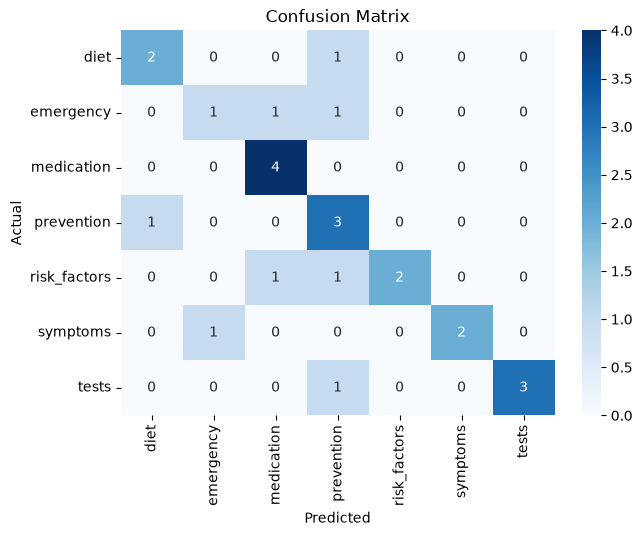

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['diet','emergency','medication',...,'risk_factors','symptoms','tests']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df.clean, df.intent, test_size=0.25, stratify=df.intent, random_state=42)

model = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 1))),
                  ("clf", LogisticRegression(C=50, max_iter=1000))])
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))   # precision, recall, F1

labels = sorted(df.intent.unique())
cm = confusion_matrix(y_test, pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix"); plt.show()

# retrain on all data for the final assistant
model.fit(df.clean, df.intent)

## Requirement 7: Domain-Specific Knowledge Base
A knowledge base with general heart-health information for **each of the 7 intent categories**, stored as a dictionary mapping each intent to a list of facts.

In [6]:
KB = {
 "symptoms": [
  "Heart attack: chest pressure or pain, pain spreading to arm/jaw/back, shortness of breath, cold sweat, nausea.",
  "Heart failure: breathlessness, fatigue, swollen ankles or legs, rapid weight gain from fluid.",
  "Arrhythmia: palpitations, dizziness, or fainting.",
  "Chest pain on exertion can signal coronary artery disease and needs medical evaluation."],
 "risk_factors": [
  "Major risk factors: smoking, high blood pressure, high cholesterol, diabetes, obesity, physical inactivity.",
  "Family history and increasing age also raise risk.",
  "Chronic stress and excess alcohol can contribute.",
  "Many risk factors are modifiable through lifestyle and treatment."],
 "prevention": [
  "Aim for about 150 minutes of moderate exercise per week (e.g. brisk walking).",
  "Quit smoking; risk begins to drop soon after quitting.",
  "Maintain a healthy weight, sleep 7-9 hours, and manage stress.",
  "Control blood pressure, cholesterol and blood sugar with regular check-ups."],
 "diet": [
  "Favour vegetables, fruits, whole grains, legumes, nuts and fish.",
  "Limit salt, sugar, processed foods, trans fats and saturated fats.",
  "The DASH and Mediterranean diets are well studied for heart health.",
  "Use unsaturated oils (olive, mustard, etc.) in moderation."],
 "medication": [
  "Statins lower LDL cholesterol; beta blockers and ACE inhibitors lower blood pressure and heart workload.",
  "Blood thinners/antiplatelets (e.g. aspirin) reduce clot risk; take only if your doctor prescribes them.",
  "Side effects vary (e.g. muscle pain with statins, dizziness or cough with BP drugs).",
  "Never start, stop or change doses without consulting your doctor."],
 "tests": [
  "ECG records the heart's electrical activity and detects rhythm problems or heart attack.",
  "Echocardiogram uses ultrasound to show heart structure and pumping function.",
  "Stress test checks heart response to exertion; angiogram visualises blocked arteries.",
  "Blood tests: lipid profile, troponin, blood sugar. Blood pressure is measured with a cuff (sphygmomanometer)."],
 "emergency": [
  "Call emergency services immediately (112 in India, 911 in US).",
  "Stop all activity and sit or lie down; loosen tight clothing.",
  "If advised by the emergency operator or a doctor, chew a regular aspirin.",
  "Do not drive yourself; if the person is unresponsive and not breathing, start CPR."],
}

## Requirement 8: Rule-Based Handling
| Rule | Description |
|---|---|
| 1. Greeting / empty / exit | Handles empty input, greetings and exit commands |
| 2. **Emergency escalation** | Emergency keywords trigger immediate emergency guidance |
| 3. **Unsupported-query handling** | Non-heart topics (skin, cancer, fever, etc.) are politely declined |
| 4. Dosage safety | Refuses to advise on medicine doses |
| 5. **Low-confidence handling** | Asks the user to rephrase if confidence < threshold or no known words |
| 6. Classifier-based emergency | Escalates if the model predicts the emergency intent |

## Requirement 9: Integrated Assistant
The function `assistant(query)` integrates:
- **NLP** (preprocessing)
- **Intent classification** (TF-IDF + Logistic Regression)
- **Reasoning** (rules + concept-graph related facts)
- **Knowledge retrieval** (knowledge base lookup)

In [7]:
THRESHOLD = 0.50   # below this confidence the assistant asks the user to rephrase

EMERGENCY_KW = ["severe chest pain", "crushing", "cannot breathe", "can't breathe", "unconscious",
    "collapsed", "fainted", "no pulse", "not breathing", "having a heart attack", "left arm",
    "call ambulance", "heart attack emergency", "emergency", "stroke now"]
HEART_TERMS = ["heart", "cardi", "chest", "cholesterol", "blood pressure", "artery", "arterial", "statin",
    "ecg", "ekg", "hypertension", "aspirin", "palpitation", "angio", "beta blocker", "ace inhibitor",
    "dash", "bp", "echocardiogram", "arrhythmia", "blood thinner", "atherosclerosis", "stroke"]
UNSUPPORTED_KW = ["diabetes", "cancer", "skin", "rash", "acne", "tooth", "dental", "fever", "covid", "cold",
    "pregnan", "kidney", "liver", "eye", "hair", "migraine", "headache", "asthma", "weather", "cricket",
    "movie", "stock", "recipe", "python"]
DOSAGE_RE = r"\b(dose|dosage|mg|milligram|how much .* (take|use))\b"
DISCLAIMER = "\n\n⚕️ Disclaimer: General information only, not a substitute for professional medical advice."

def related_facts(ql, limit=3):                      # reasoning over concept graph
    out = [f"{s} {r} {o}" for s, r, o in TRIPLES if s.lower() in ql or o.lower() in ql]
    return out[:limit]

def assistant(query, verbose=True):
    q = query.strip().replace("’", "'"); ql = q.lower()
    # Rule 1: empty / greeting / exit
    if not q: return "Please type a question about heart health."
    if ql in {"exit", "quit", "bye"}: return "Take care of your heart! Goodbye 👋"
    if ql in {"hi", "hello", "hey"}: return "Hello! I'm the Heart Health Assistant. Ask me about symptoms, risks, diet, medicines, tests or prevention."
    # Rule 2: emergency escalation
    if any(k in ql for k in EMERGENCY_KW):
        return "🚨 POSSIBLE EMERGENCY 🚨\n• " + "\n• ".join(KB["emergency"])
    # Rule 3: unsupported query
    has_heart = any(h in ql for h in HEART_TERMS)
    if any(u in ql for u in UNSUPPORTED_KW) and not has_heart:
        return "Sorry, I only handle heart-health questions. For other topics please consult a relevant doctor or resource."
    # Rule 4: dosage safety
    if re.search(DOSAGE_RE, ql):
        return "I can't advise on medicine doses. Please follow your doctor's or pharmacist's prescription." + DISCLAIMER
    # Classification
    clean = preprocess(q)
    vocab = model.named_steps["tfidf"].vocabulary_
    probs = model.predict_proba([clean])[0]
    i = probs.argmax(); intent, conf = model.classes_[i], probs[i]
    # Rule 5: low-confidence handling
    if not any(t in vocab for t in clean.split()) or conf < THRESHOLD:
        return f"I'm not sure I understood (confidence {conf:.2f}). Could you rephrase, e.g. ask about heart symptoms, diet, medicines, tests or risk factors?"
    # Rule 6: classifier-detected emergency
    if intent == "emergency":
        return "🚨 POSSIBLE EMERGENCY 🚨\n• " + "\n• ".join(KB["emergency"])
    # Knowledge retrieval + reasoning
    cat, sub = INTENT_TAXONOMY[intent]
    ans = f"[{cat} > {sub} | intent={intent} | confidence={conf:.2f}]\n• " + "\n• ".join(KB[intent])
    rel = related_facts(ql)
    if rel: ans += "\n\n🔗 Related: " + "; ".join(rel)
    return ans + DISCLAIMER

## Requirement 10: Interactive Interface (Google Colab)
Interactive ipywidgets interface that accepts **multiple queries** in a row and displays the assistant's response for each. Type a question and click **Ask** (or press Enter).

In [8]:
import ipywidgets as widgets
from IPython.display import display

box = widgets.Text(placeholder="Ask a heart health question...", layout=widgets.Layout(width="70%"))
btn = widgets.Button(description="Ask", button_style="primary")
out = widgets.Output()

def on_ask(_):
    q = box.value
    if not q.strip(): return
    with out:
        print("🧑 You:", q); print("🤖 Assistant:", assistant(q)); print("-" * 70)
    box.value = ""

btn.on_click(on_ask)
box.on_submit(on_ask)
display(widgets.HBox([box, btn]), out)

/var/folders/d0/0wb_r2f169532hdqxztk00gr0000gn/T/ipykernel_42427/1713143511.py:16: DeprecationWarning: on_submit is deprecated. Instead, set the .continuous_update attribute to False and observe the value changing with: mywidget.observe(callback, 'value').
  box.on_submit(on_ask)


Output()

## Testing the Assistant
| # | Test | Query type |
|---|---|---|
| 1 | Query for each defined intent | 7 queries |
| 2 | Differently worded query | Paraphrased queries |
| 3 | Unsupported healthcare query | Skin rash |
| 4 | Low-confidence query | Vague query |
| 5 | Emergency-related query | Chest pain with breathlessness |

In [9]:
tests = {
 "Intent: symptoms":    "What are the symptoms of a heart attack?",
 "Intent: risk_factors":"Does smoking increase the risk of heart attack?",
 "Intent: prevention":  "How can I prevent heart disease?",
 "Intent: diet":        "What foods are good for heart health?",
 "Intent: medication":  "What do statins do?",
 "Intent: tests":       "What is an ECG test?",
 "Intent: emergency":   "I think I am having a heart attack",
 "Differently worded 1":"Which meals should I choose for a healthy heart?",
 "Differently worded 2":"What can make a person more likely to get cardiac problems?",
 "Unsupported":         "How do I treat a skin rash?",
 "Low confidence":      "Tell me about health",
 "Emergency":           "I am having severe chest pain and cannot breathe",
}
for name, q in tests.items():
    print(f"### {name}\nQ: {q}\nA: {assistant(q)}\n" + "=" * 70)

### Intent: symptoms
Q: What are the symptoms of a heart attack?
A: [Condition Awareness > Symptoms | intent=symptoms | confidence=0.94]
• Heart attack: chest pressure or pain, pain spreading to arm/jaw/back, shortness of breath, cold sweat, nausea.
• Heart failure: breathlessness, fatigue, swollen ankles or legs, rapid weight gain from fluid.
• Arrhythmia: palpitations, dizziness, or fainting.
• Chest pain on exertion can signal coronary artery disease and needs medical evaluation.

🔗 Related: Coronary Artery Disease can cause Heart Attack; Heart Attack presents with Chest Pain; ECG detects Heart Attack

⚕️ Disclaimer: General information only, not a substitute for professional medical advice.
### Intent: risk_factors
Q: Does smoking increase the risk of heart attack?
A: [Condition Awareness > Risk Factors | intent=risk_factors | confidence=0.93]
• Major risk factors: smoking, high blood pressure, high cholesterol, diabetes, obesity, physical inactivity.
• Family history and increasin